# **Deep Learning Lab 1 - Raja Rayyan Ameer - 23-CP-25**

In [28]:
import sys
import numpy as np
import torch
import tensorflow as tf
import time
import matplotlib.pyplot as plt

### **Task 1: Environment SetUp and Version Check**

In [29]:
print('Python: ',sys.version.split()[0])
print('Numpy: ',np.__version__)
print('PyTorch: ',torch.__version__)
print('TF: ',tf.__version__)

Python:  3.13.15
Numpy:  2.1.3
PyTorch:  2.11.0+cu128
TF:  2.20.0


### **Task 2: GPU Verification and CPU vs GPU Benchmark**

CUDA available: True
Device name : Tesla T4
n=500: CPU=0.0028s  GPU=0.0002s  speed-up=15.9x
n=1000: CPU=0.0171s  GPU=0.0008s  speed-up=21.0x
n=2000: CPU=0.1279s  GPU=0.0058s  speed-up=22.2x
n=4000: CPU=1.2299s  GPU=0.0444s  speed-up=27.7x


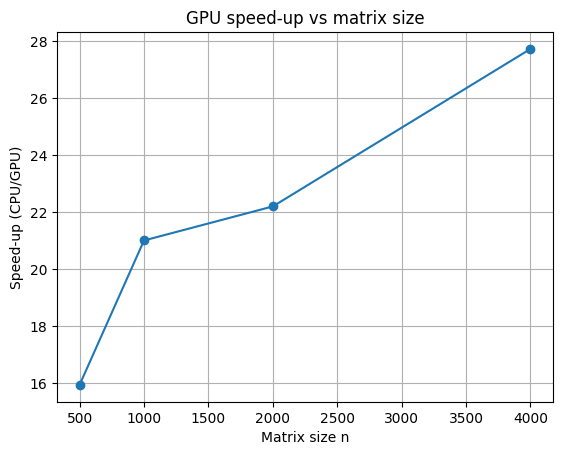

In [30]:
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('Device name :', torch.cuda.get_device_name(0))

def benchmark(device, n, repeats=3):
    a = torch.randn(n, n, device=device)
    b = torch.randn(n, n, device=device)

    if device == 'cuda':
      torch.cuda.synchronize()

    t0 = time.time()

    for _ in range(repeats):
        c = a @ b

    if device == 'cuda':
      torch.cuda.synchronize()

    return (time.time() - t0) / repeats

sizes = [500, 1000, 2000, 4000]
speedups = []

for n in sizes:
    t_cpu = benchmark('cpu', n)

    if torch.cuda.is_available():
        t_gpu = benchmark('cuda', n)
        sp = t_cpu / t_gpu
        speedups.append(sp)
        print(f'n={n}: CPU={t_cpu:.4f}s  GPU={t_gpu:.4f}s  speed-up={sp:.1f}x')

    else:
        print(f'n={n}: CPU={t_cpu:.4f}s  (no GPU)')

plt.plot(sizes, speedups, marker='o')
plt.xlabel('Matrix size n')
plt.ylabel('Speed-up (CPU/GPU)')
plt.title('GPU speed-up vs matrix size')
plt.grid(True)
plt.show()

### **Task 3: Vectorization: Removing Loops**

**Element-Wise**

In [31]:
x = np.random.randn(100_000)

# Loop version
t0 = time.time()
sig_loop = np.zeros_like(x)

for i in range(len(x)):
    sig_loop[i] = 1.0 / (1.0 + np.exp(-x[i]))

t_loop = time.time() - t0

# Vectorized version
t0 = time.time()
sig_vec = 1.0 / (1.0 + np.exp(-x))
t_vec = time.time() - t0

print(f'Loop: {t_loop*1000:.1f} ms Vector: {t_vec*1000:.3f} ms SpeedUp: {t_loop/t_vec:.0f}x')
print('Max Difference:', np.max(np.abs(sig_loop - sig_vec)))

Loop: 282.5 ms Vector: 0.814 ms SpeedUp: 347x
Max Difference: 0.0


**Column-Wise**

In [32]:
M = np.random.randn(1000, 50)

# Loop version
t0 = time.time()
means_loop = np.zeros(50)

for j in range(50):
    s = 0.0

    for i in range(1000):
        s += M[i, j]

    means_loop[j] = s / 1000

t_loop = time.time() - t0

# Vectorized version
t0 = time.time()
means_vec = M.mean(axis=0)
t_vec = time.time() - t0

print(f'Loop: {t_loop*1000:.1f} ms Vector: {t_vec*1000:.3f} ms SpeedUp: {t_loop/t_vec:.0f}x')
print('Max Difference:', np.max(np.abs(means_loop - means_vec)))

Loop: 38.0 ms Vector: 0.342 ms SpeedUp: 111x
Max Difference: 0.0


### **Task 4: Broadcasting**

In [33]:
A = np.array([[56.0, 0.0, 4.4, 68.0], [ 1.2, 104.0, 52.0, 8.0], [ 1.8, 135.0, 99.0, 0.9]])

col_sum = A.sum(axis=0)          # shape (4,)
percent = 100 * A / col_sum      # (3,4) / (4,) -> broadcast

print('Percent: ', percent)

Percent:  [[94.91525424  0.          2.83140283 88.42652796]
 [ 2.03389831 43.51464435 33.46203346 10.40312094]
 [ 3.05084746 56.48535565 63.70656371  1.17035111]]


**1.** **Predict the resulting shape of each operation below, then run it and state whether your prediction was correct: (i) shape (4,1) + shape (1,3); (ii) shape (3,4) + shape (4,); (iii) shape (3,4) + shape (3,); (iv) shape (5,1) * shape (5,).**

In [34]:
print((np.zeros((4,1)) + np.zeros((1,3))).shape)   # (4,3)
print((np.zeros((3,4)) + np.zeros((4,))).shape)    # (3,4)
#print((np.zeros((3,4)) + np.zeros((3,))).shape)  # ERROR
print((np.zeros((5,1)) * np.zeros((5,))).shape)    # (5,5)

(4, 3)
(3, 4)
(5, 5)


**2.** **One of the above raises an error and one produces a surprising 5 × 5 result. Identify both and explain, using the broadcasting rules, why each behaves that way.**

* **(3,4) + (3,) → Error:** (3,) is treated as (1,3). Aligning from the right: 4 vs 3 mismatch → not broadcastable.

* **(5,1) * (5,) → (5,5) surprising result:** (5,) is treated as (1,5). Then (5,1) and (1,5) broadcast to (5,5) an outer product, not what you likely intended.

**3.** **Create a = np.random.randn(5) and print a.shape, a.T.shape and np.dot(a, a.T). Then create b = np.random.randn(5,1) and print the same three quantities. Explain why rank-1 arrays are discouraged in deep learning code and what should be used instead.**

In [35]:
a = np.random.randn(5)
print(a.shape, a.T.shape, np.dot(a, a.T).shape)
# (5,) (5,) ()   <- a.T is still (5,)! dot gives a scalar

b = np.random.randn(5,1)
print(b.shape, b.T.shape, np.dot(b, b.T).shape)
# (5,1) (1,5) (5,5)

(5,) (5,) ()
(5, 1) (1, 5) (5, 5)


### **Task 5: Tensors and Device Transfer**

In [36]:
t1 = torch.zeros(2, 3)
t2 = torch.ones(2, 3)
t3 = torch.randn(2, 3)

print(t3, t3.shape, t3.dtype, t3.device)

n = np.array([[1., 2.], [3., 4.]])          # NumPy -> tensor
t = torch.from_numpy(n)

back = t.numpy()                            # tensor -> NumPy
device = 'cuda' if torch.cuda.is_available() else 'cpu'
t_gpu = t3.to(device)

print('On Device:', t_gpu.device)

tensor([[-0.4019,  0.3214, -0.5256],
        [ 0.4514, -0.2185,  0.4196]]) torch.Size([2, 3]) torch.float32 cpu
On Device: cuda:0


**1. Create two 3 × 3 tensors and compute their element-wise product and their matrix product. State clearly how the two results differ.**

In [37]:
A = torch.randn(3, 3)
B = torch.randn(3, 3)

elem = A * B       # element-wise (Hadamard) product
mat  = A @ B       # matrix product

print('Element-wise:\n', elem)
print('Matrix product:\n', mat)

Element-wise:
 tensor([[-0.7363,  0.7864, -0.7646],
        [ 0.3650, -0.1549, -0.0133],
        [-1.5211,  1.0886, -0.1227]])
Matrix product:
 tensor([[ 1.0233,  0.7257,  1.3767],
        [ 0.1774,  0.2727, -0.4203],
        [-0.3918, -0.1967,  1.3014]])


**2. Reshape a tensor of 12 elements into shapes (3,4), (4,3) and (2,2,3) and print each.**

In [38]:
t = torch.arange(12.)

print(t.reshape(3,4))
print(t.reshape(4,3))
print(t.reshape(2,2,3))

tensor([[ 0.,  1.,  2.,  3.],
        [ 4.,  5.,  6.,  7.],
        [ 8.,  9., 10., 11.]])
tensor([[ 0.,  1.,  2.],
        [ 3.,  4.,  5.],
        [ 6.,  7.,  8.],
        [ 9., 10., 11.]])
tensor([[[ 0.,  1.,  2.],
         [ 3.,  4.,  5.]],

        [[ 6.,  7.,  8.],
         [ 9., 10., 11.]]])


**3. Attempt to add a CPU tensor to a GPU tensor. Copy the exact error message into the notebook and explain in one sentence what it means.**

In [40]:
cpu_t = torch.randn(3, 3)
gpu_t = torch.randn(3, 3, device='cuda')
cpu_t.to('cuda') + gpu_t

tensor([[ 2.5967, -2.7746, -0.3233],
        [-0.2077,  2.3122,  0.0737],
        [ 0.3375,  3.1319, -0.8136]], device='cuda:0')

### **Task 6: Automatic Differentiation (Autograd)**

In [41]:
x = torch.tensor(3.0, requires_grad=True)
y = x**2 + 5*x + 2                           # dy/dx = 2x + 5 -> 11 at x = 3
y.backward()

print('dy/dx at x=3 :', x.grad.item())

# Vector input, scalar output
w = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
z = (w**2).sum() # dz/dw = 2w
z.backward()

print('dz/dw :', w.grad)

dy/dx at x=3 : 11.0
dz/dw : tensor([2., 4., 6.])


**1. For f(x) = x³ − 4x² + 7, compute the derivative with autograd at x = 2 and x = −1. Verify both against the analytical derivative computed by hand, and show the hand calculation in a markdown cell.**

In [42]:
for xv in [2.0, -1.0]:
    x = torch.tensor(xv, requires_grad=True)
    f = x**3 - 4*x**2 + 7
    f.backward()

    print(f'x={xv}: Autograd={x.grad.item():.4f}  Analytic={3*xv**2 - 8*xv:.4f}')

x=2.0: Autograd=-4.0000  Analytic=-4.0000
x=-1.0: Autograd=11.0000  Analytic=11.0000


**2. Define a simple linear model ŷ = wx + b with w = 2.0, b = 1.0 (both requiring gradients) and the squared error loss L = (ŷ − y)² for x = 3.0, y = 10.0. Compute ∂L/∂w and ∂L/∂b using autograd and verify them by hand.**

In [43]:
w = torch.tensor(2.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)
x, y = 3.0, 10.0

yhat = w*x + b
L = (yhat - y)**2
L.backward()

print('dL/dw =', w.grad.item())  # -18
print('dL/db =', b.grad.item())  # -6

dL/dw = -18.0
dL/db = -6.0


**3. Call backward a second time without clearing the gradients and observe the value of w.grad. Explain why gradients accumulate and state the function used to reset them before the next iteration.**

In [45]:
w = torch.tensor(2.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

yhat = w*3 + b
L = (yhat - 10)**2
L.backward(retain_graph=True)

print('After 1st Backward:', w.grad.item())   # -18
L.backward()
print('After 2nd Backward:', w.grad.item())   # -36  (accumulated!)

After 1st Backward: -18.0
After 2nd Backward: -36.0


### **Task 7: Open Exercise: Vectorized Distance Matrix**

**Hint: Consider the expansion ‖p − q‖² = ‖p‖² + ‖q‖² − 2p·q, and use array shapes (200,1) and (1,200) to obtain the pairwise terms.**

In [46]:
np.random.seed(0)
X = np.random.randn(200, 3)
N = X.shape[0]

**1. Write a nested-loop implementation and time it.**

In [47]:
t0 = time.time()
D_loop = np.zeros((N, N))

for i in range(N):
    for j in range(N):
        diff = X[i] - X[j]
        D_loop[i, j] = np.sqrt((diff**2).sum())

t_loop = time.time() - t0

**2. Write a fully vectorized implementation using broadcasting only (no loops) and time it.**

In [48]:
t0 = time.time()
sq = (X**2).sum(axis=1)                        # shape (200,)
D2 = sq[:, None] + sq[None, :] - 2 * X @ X.T   # (200,1)+(1,200)-2(200,200)
D2 = np.maximum(D2, 0)                         # clip tiny negatives from roundoff
D_vec = np.sqrt(D2)
t_vec = time.time() - t0

**3. Verify that both results agree to within a small numerical tolerance, and report the speed-up factor.**

In [49]:
print(f'Loop: {t_loop*1000:.1f} ms Vector: {t_vec*1000:.3f} ms SpeedUp: {t_loop/t_vec:.0f}x')
print('Max Difference:', np.max(np.abs(D_loop - D_vec)))
print('Diagonal ~ 0:', np.allclose(np.diag(D_vec), 0, atol=1e-10))

Loop: 181.1 ms Vector: 2.745 ms SpeedUp: 66x
Max Difference: 5.960464477539063e-08
Diagonal ~ 0: False
